<h1>Практическая работа: "Бинарная логистическая регрессия"</h1>

__Задача бинарной классификации__

___Некая фирма провела анализ зависимости расхода денежных средств на рекламу и эффекта от нее. Если эффект присутствовал, 
то в датасете ставилась 1, в противном случае - 0. Результаты были представоены в виде двух DataFrame х и y.<br>
Произыести бинарную классификацию с использованием логистической регрессии.___  

In [1]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
#display(x, Y)

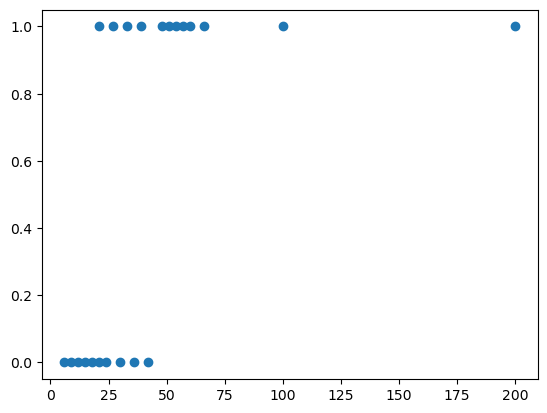

In [4]:
plt.scatter(x,Y)

_Попробуем разделить эти точки прямой линией, отделяющей один класс от другого. 
Модель начинает плохо работать в случае добавления новых точек на больших значениях x:_

In [5]:
a1 = ((x-x.mean())*(Y-Y.mean())).mean()/((x-x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Y = ", a0, " + ", a1, " * x")
x_space = np.linspace(6,70,20)
Y_pred = a0.item() + a1.item()*x_space

Y =  0    0.266493
dtype: float64  +  0    0.006333
dtype: float64  * x


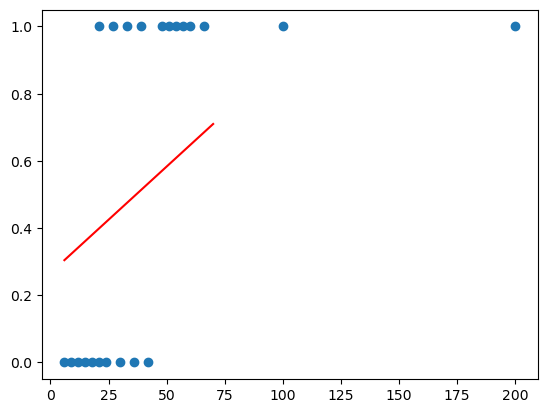

In [6]:
plt.plot(x_space, Y_pred, 'r')
plt.scatter(x, Y)

<h2>Функция логистической регрессии</h2>

__Сигмоида__

Возможное решение упомянутых выше сложностей — пропустить значение линейной регрессии через сигмоиду (sigmoid function), 
которая при любом значении x не выйдет из необходимого нам диапазона от 0 до 1. <br>
<h3>$g(x) = \frac{1}{1+ e^{-x}}$</h3>

 <img src='images/ris1.png' width=320, heigth=240>

<h3>Logistic loss или функция кросс-энтропии</h3>

В модели логистической регрессии мы не можем использовать MSE. Дело в том, 
что если мы поместим результат сигмоиды (представляющей собою нелинейную функцию) в MSE, 
то на выходе получим невыпуклую функцию (non-convex), глобальный минимум которой довольно сложно найти.
 <img src='images/ris2.png' width=520, heigth=240>
    Вместо MSE мы будем использовать функцию логистической ошибки, которую еще называют функцией бинарной кросс-энтропии (log loss, binary cross-entropy loss).

__График и формула функции логистической ошибки__<br>
 <img src='images/ris3.png' width=420, heigth=240>

$J(\theta)=-\frac{1}{n} \sum{y*log(h_{\theta}(x))+(1-y)*log(1-h_{\theta}(x))}$

<h3>Оценка качества модели</h3>

__Матрицa ошибок (confusion matrix)__<br>
 <img src='images/ris4.png' width=420, heigth=240><br>
Доля правильно предсказанных значений называется accuracy. Чтобы ее посчитать, мы берем те значения,
    которые предсказаны верно (TP + TN) и делим на общее количество прогнозов.<br>
    <h3>$accuracy=\frac{TP+TN}{TP+TN+FP+FN}$</h3>

<h2>Конкретизация задачи:</h2>

Реализовать класс модели логистической регрессии с использованием:

а) максимизации логарифмического правдоподобия методом градиентного подъема

б) минимизации функции потерь (кросс-энтропии) методом градиентного спуска

Сравнить результаты (время исполнения и достигнутые значения accuracy и f1) в случаях а и б при одном и том же числе шагов и скорости обучения.

In [7]:
#Реализуем цикл градиентного спуска
class LogisticRegressionGD(object):
    def __init__(self):
        self.a = np.zeros(2).reshape(1, 2)
        
    def sigmoid(self, x):
        return 1/(1 + np.exp(-x @ self.a))
    
    def predict(self, x):
        return self.sigmoid(x)
    
    def coefs(self):
        return self.a
      
    def LogLikelihood(self, x, Y):
        return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()

    def CrossEntropy(self, x, Y):
        return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()
    
    def accuracy(self, x, Y):
        return ((self.predict(x) > 0.5)==Y).mean() 

    def fit(self, x, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL"):
        self.a = np.zeros (x.shape[1]).reshape(x.shape[1],1)
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            if Rtype == "LL":
                new_error = self.LogLikelihood(x, Y)
                dT_a = x.T @(Y - self.predict(x)) / x.shape[0]
                self.a += alpha*dT_a
            elif Rtype == "CE":
                new_error = self.CrossEntropy(x, Y)
                #display(new_error)
                dT_a = -x.T @(Y - self.predict(x)) / x.shape[0]
                self.a -= alpha*dT_a
            step += 1
            steps.append(step)
            errors.append(new_error)
            #if new_error < epsylon:
            #    break
        return steps, errors

In [8]:
x_ = x.copy()

import time

intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis = 1))

In [117]:
start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE =  regr_CE.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "CE") 

display(f"Время обучения: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL =  regr_LL.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL") 

display(f"Время обучения: {time.time() - start_time_LL} сек.")

'Время обучения: 51.10913443565369 сек.'

'Время обучения: 54.79919672012329 сек.'

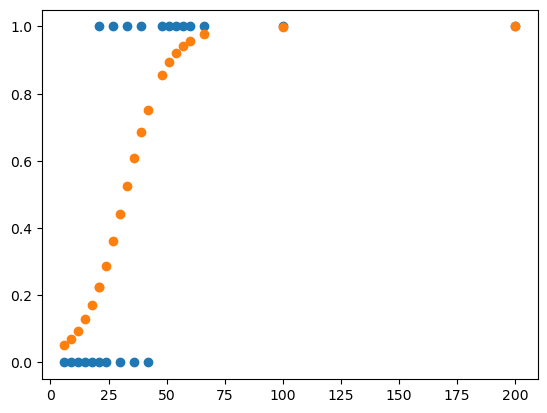

In [118]:
Y_Pred = regr_CE.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [126]:
display(regr_CE.coefs())
#display(x_)

,0
0,-3.598810
1,0.112152


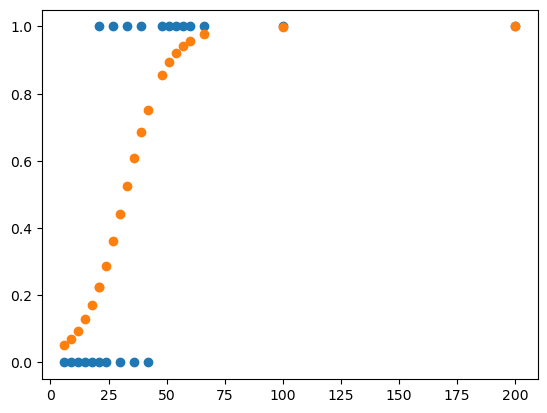

In [120]:
Y_Pred = regr_LL.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [125]:
display(regr_LL.coefs())
#display(x_)

,0
0,-3.598810
1,0.112152


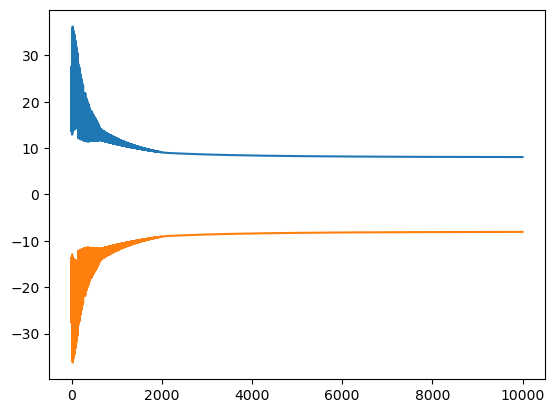

In [122]:
plt.plot(steps_CE, errors_CE)
plt.plot(steps_LL, errors_LL)

In [123]:
print(regr_CE.accuracy(x_, Y))
print(regr_LL.accuracy(x_, Y))

0    0.818182
dtype: float64
0    0.818182
dtype: float64


Реализовать расчеты способами а и б для набора данных из файла insclass_train.csv/
Для 151 406 договоров страхования транспортных средств известны значения ряда признаков, в том числе пол, возраст, стаж вождения и коэффициент бонус-малус водителя, тип, марка, модель, год выпуска, страна – производитель, мощность и объем двигателя, а также признак target, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае (файл insclass_train.csv).

Требуется построить модель, предсказывающую значение признака target для 22 624 договоров из тестового набора данных (файл insclass_test.csv).

В обучающем наборе данных для каждого договора известны следующие поля:

variable_1 - агрегированный коэффициент бонус-малус (повышающий или понижающий стоимость полиса в зависимости от аварийности в предыдущие периоды);
variable_2 - индикатор расторжения договора по инициативе страхователя (клиента);
variable_3 - индикатор расторжения договора по инициативе страховщика (страховой компании);
variable_4 - идентификатор года выпуска транспортного средства;
variable_5 - идентификатор страны - производителя транспортного средства;
variable_6 - мощность двигателя в лошадиных силах;
variable_7 - объем двигателя в куб. см;
variable_8 - идентификатор стороны расположения руля (левый или правый);
variable_9 - пробег транспортного средства, покрываемый гарантией производителя;
variable_10 - индикатор действия гарантии на транспортное средство;
variable_11 - "мультидрайв" - индикатор допуска к управлению транспортным средством более одного водителя;
variable_12 - возраст транспортного средства (в мес.);
variable_13 - возраст водителя с максимальным стажем;
variable_14 - коэффициент возраст-стаж;
variable_15 - коэффициент краткосрочности;
variable_16 - коэффициент мощности;
variable_17 - коэффициент "мультидрайв";
variable_18 - территориальный коэффициент;
variable_19 - коэффициент "КНДР";
variable_20 - идентификатор канала продаж;
variable_21 - марка транспортного средства;
variable_22 - модель транспортного средства;
variable_23 - индикатор отечественных транспортных средств;
variable_24 - пол водителя с максимальным коэффициентом "возраст-стаж";
variable_25 - индикатор пролонгации;
variable_26 - индикатор совпадения собственника транспортного средства и водителя;
variable_27 - стаж водителя с максимальным коэффициентом "возраст-стаж";
variable_28 - тип транспортного средства;
target - класс риска, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае.

<h2>Решение задачи на датасете <code>insclass_train.csv</code> (способы а и б)</h2>

### 1. Первичный анализ данных и разделение параметров (признаков) по типам

В файле `insclass_train.csv` содержится **151 406 договоров страхования** и **29 столбцов** (`variable_1` … `variable_28` и целевой признак `target`). Перед подачей данных в градиентный спуск/подъем логистической регрессии необходимо **разделить (отделить) параметры на группы** по их физической природе, типу данных и информативности:

1. **Неинформативные и пустые признаки (удаляются — 4 признака)**:
   - `variable_3` — константный признак (принимает только одно значение `0` во всех 151 406 строках, нулевая дисперсия);
   - `variable_15` — **99.99% пропусков** (151 393 `NaN` из 151 406);
   - `variable_9` — **88.79% пропусков** (134 436 `NaN`);
   - `variable_7` — **63.17% пропусков** (95 639 `NaN`).
2. **Категориальные строковые признаки (`dtype == object`) — разделяются по кардинальности**:
   - **Низкокардинальные категориальные (4 признака)**: `variable_1` (15 категорий бонус-малус `w...`), `variable_5` (39 стран-производителей `q...`), `variable_20` (3 канала продаж `A, B, C`), `variable_28` (5 типов ТС `t1..t5`) $\rightarrow$ кодируются методом **One-Hot Encoding (`pd.get_dummies(..., drop_first=True)`)**.
   - **Высококардинальные категориальные (2 признака)**: `variable_21` (192 марки ТС `j...`) и `variable_22` (1475 моделей ТС `h...`) $\rightarrow$ отделяются от обычных категориальных, так как One-Hot Encoding создал бы $1667$ лишних разреженных столбцов; для них применяется **Frequency Encoding** (замена категории частотой ее встречаемости в выборке).
3. **Бинарные индикаторные признаки (`0`/`1` — 9 признаков)**:
   - `variable_2`, `variable_8`, `variable_10`, `variable_11`, `variable_17`, `variable_23`, `variable_24`, `variable_25`, `variable_26` $\rightarrow$ пропуски заполняются медианой (`0.0`).
4. **Количественные (непрерывные и дискретные числовые) признаки (9 признаков)**:
   - `variable_4`, `variable_6`, `variable_12`, `variable_13`, `variable_14`, `variable_16`, `variable_18`, `variable_19`, `variable_27` $\rightarrow$ пропуски заполняются медианой, после чего вся матрица признаков масштабируется через **`StandardScaler`** ($\mu=0, \sigma=1$), чтобы исключить переполнение экспоненты $\exp(-X a)$ в сигмоиде.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve

df_ins = pd.read_csv("insclass_train.csv")
print(f"Размер датасета insclass_train.csv: {df_ins.shape}")
vc = df_ins["target"].value_counts()
print("Распределение целевого признака target:")
print(f"0: {vc[0]} ({vc[0]/len(df_ins)*100:.2f}%)")
print(f"1: {vc[1]}  ({vc[1]/len(df_ins)*100:.2f}%)\n")

dropped_cols = ["variable_3", "variable_7", "variable_9", "variable_15"]
cat_low_cols = ["variable_1", "variable_5", "variable_20", "variable_28"]
cat_high_cols = ["variable_21", "variable_22"]
binary_cols = [
    "variable_2", "variable_8", "variable_10", "variable_11", "variable_17",
    "variable_23", "variable_24", "variable_25", "variable_26"
]
numeric_cols = [
    "variable_4", "variable_6", "variable_12", "variable_13", "variable_14",
    "variable_16", "variable_18", "variable_19", "variable_27"
]

print("Группы признаков:")
print(f"  Удаленные (константные и >60% NaN): {dropped_cols}")
print(f"  Категориальные (One-Hot):           {cat_low_cols}")
print(f"  Категориальные (Frequency):         {cat_high_cols}")
print(f"  Бинарные индикаторы (0/1):          {binary_cols}")
print(f"  Числовые (StandardScaler):          {numeric_cols}\n")

df_clean = df_ins.drop(columns=dropped_cols).copy()

for col in numeric_cols + binary_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in cat_low_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

for col in cat_high_cols:
    freq_map = df_clean[col].value_counts(normalize=True)
    df_clean[col] = df_clean[col].map(freq_map).astype(np.float64)

df_encoded = pd.get_dummies(df_clean, columns=cat_low_cols, drop_first=True, dtype=np.float64)

X_all = df_encoded.drop(columns=["target"]).values.astype(np.float64)
y_all = df_encoded["target"].values.reshape(-1, 1).astype(np.float64)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

X_train_b = np.hstack([np.ones((X_train_sc.shape[0], 1)), X_train_sc])
X_test_b = np.hstack([np.ones((X_test_sc.shape[0], 1)), X_test_sc])

print("Размер матриц после предобработки и добавления столбца единиц (intercept):")
print(f"  X_train_b: {X_train_b.shape}, y_train: {y_train.shape}")
print(f"  X_test_b:  {X_test_b.shape},  y_test:  {y_test.shape}")

Размер датасета insclass_train.csv: (151406, 29)
Распределение целевого признака target:
0: 136947 (90.45%)
1: 14459  (9.55%)

Группы признаков:
  Удаленные (константные и >60% NaN): ["variable_3", "variable_7", "variable_9", "variable_15"]
  Категориальные (One-Hot):           ["variable_1", "variable_5", "variable_20", "variable_28"]
  Категориальные (Frequency):         ["variable_21", "variable_22"]
  Бинарные индикаторы (0/1):          ["variable_2", "variable_8", "variable_10", "variable_11", "variable_17", "variable_23", "variable_24", "variable_25", "variable_26"]
  Числовые (StandardScaler):          ["variable_4", "variable_6", "variable_12", "variable_13", "variable_14", "variable_16", "variable_18", "variable_19", "variable_27"]

Размер матриц после предобработки и добавления столбца единиц (intercept):
  X_train_b: (121124, 79), y_train: (121124, 1)
  X_test_b:  (30282, 79),  y_test:  (30282, 1)


                     Метод  Время (сек)  Accuracy (train)  Accuracy (test, thr=0.5)  F1 (test, thr=0.5)  F1 (test, thr=0.15)  ROC-AUC (test)
а) Градиентный подъем (LL)       7.1930            0.9116                    0.9115              0.2086               0.2582          0.6631
 б) Градиентный спуск (CE)       7.2626            0.9116                    0.9115              0.2086               0.2582          0.6631

Норма разности векторов весов ||a_LL - a_CE||_2 = 0.000e+00


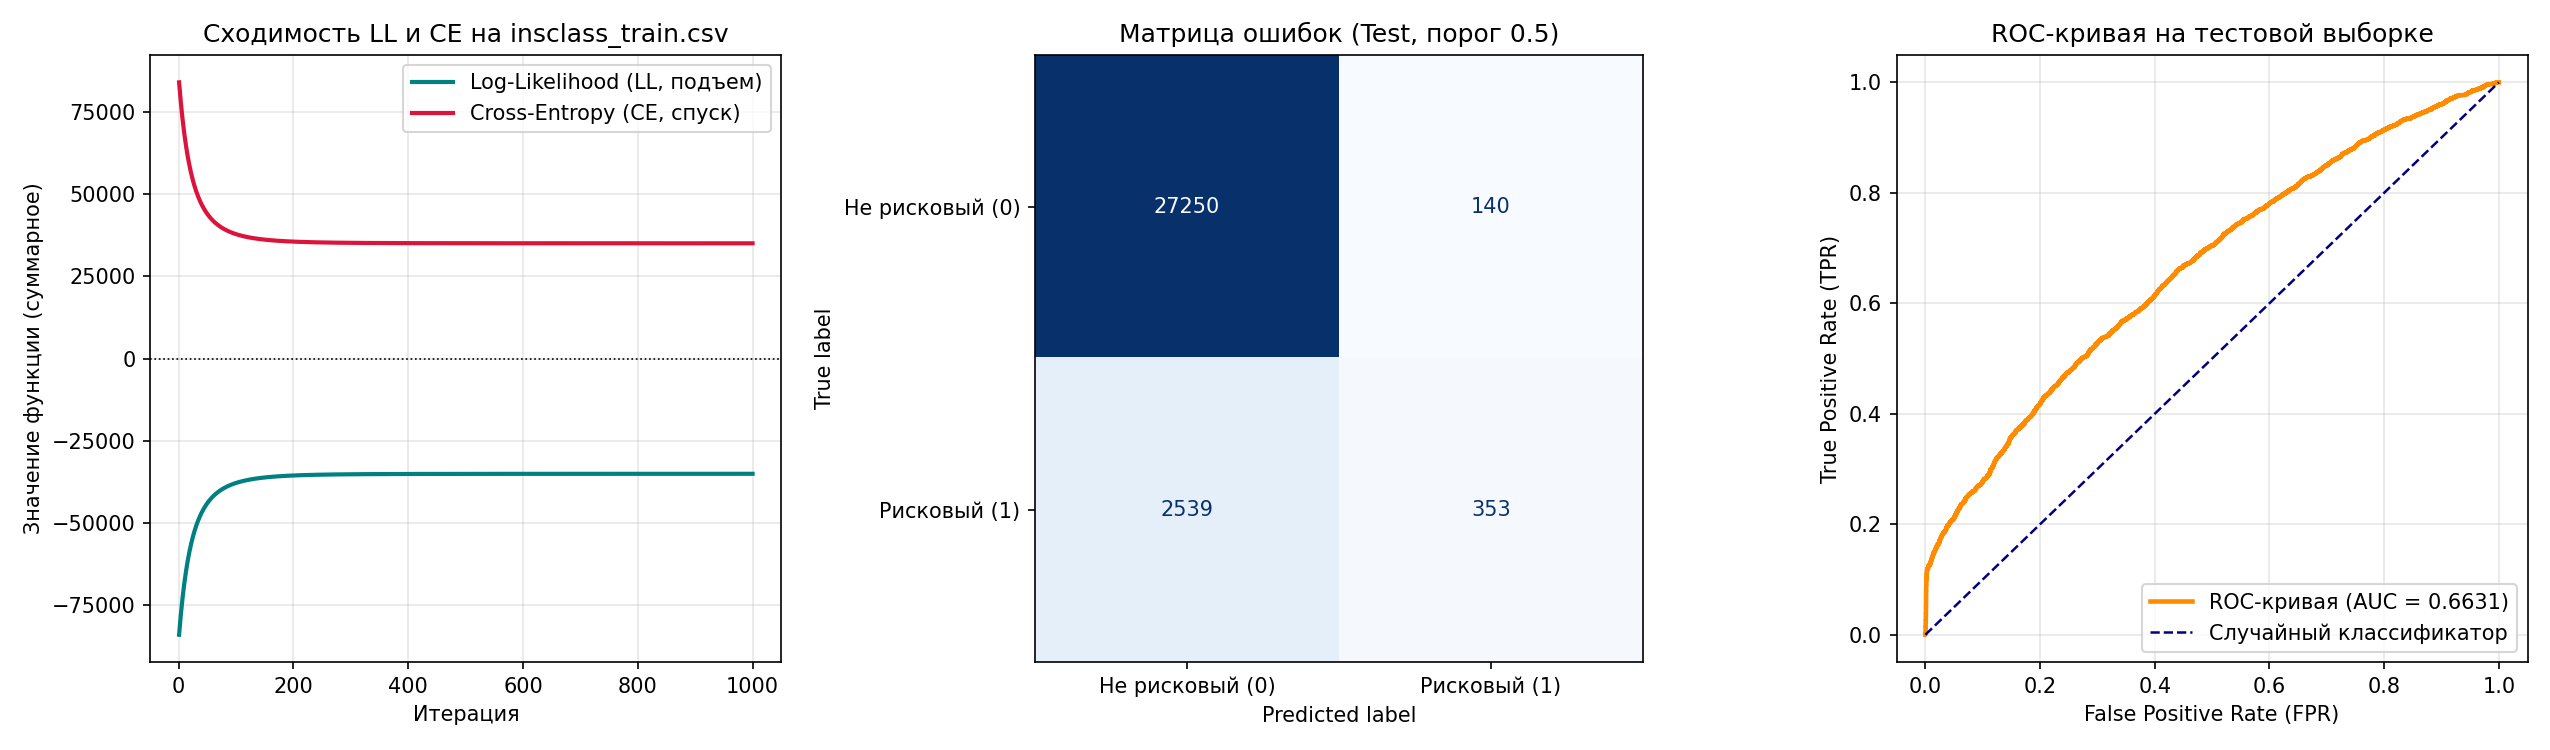

In [ ]:
alpha_ins = 0.1
max_steps_ins = 1000

t0_ll = time.time()
ins_LL = LogisticRegressionGD()
steps_ins_LL, errors_ins_LL = ins_LL.fit(X_train_b, y_train, alpha=alpha_ins, max_steps=max_steps_ins, Rtype="LL")
time_ins_LL = time.time() - t0_ll

t0_ce = time.time()
ins_CE = LogisticRegressionGD()
steps_ins_CE, errors_ins_CE = ins_CE.fit(X_train_b, y_train, alpha=alpha_ins, max_steps=max_steps_ins, Rtype="CE")
time_ins_CE = time.time() - t0_ce

prob_test_LL = ins_LL.predict(X_test_b).ravel()
prob_test_CE = ins_CE.predict(X_test_b).ravel()

results_ins = pd.DataFrame([
    {
        "Метод": "а) Градиентный подъем (LL)",
        "Время (сек)": round(time_ins_LL, 4),
        "Accuracy (train)": round(ins_LL.accuracy(X_train_b, y_train), 4),
        "Accuracy (test, thr=0.5)": round(ins_LL.accuracy(X_test_b, y_test), 4),
        "F1 (test, thr=0.5)": round(f1_score(y_test.ravel(), (prob_test_LL > 0.5).astype(int)), 4),
        "F1 (test, thr=0.15)": round(f1_score(y_test.ravel(), (prob_test_LL > 0.15).astype(int)), 4),
        "ROC-AUC (test)": round(roc_auc_score(y_test.ravel(), prob_test_LL), 4),
    },
    {
        "Метод": "б) Градиентный спуск (CE)",
        "Время (сек)": round(time_ins_CE, 4),
        "Accuracy (train)": round(ins_CE.accuracy(X_train_b, y_train), 4),
        "Accuracy (test, thr=0.5)": round(ins_CE.accuracy(X_test_b, y_test), 4),
        "F1 (test, thr=0.5)": round(f1_score(y_test.ravel(), (prob_test_CE > 0.5).astype(int)), 4),
        "F1 (test, thr=0.15)": round(f1_score(y_test.ravel(), (prob_test_CE > 0.15).astype(int)), 4),
        "ROC-AUC (test)": round(roc_auc_score(y_test.ravel(), prob_test_CE), 4),
    }
])
print(results_ins.to_string(index=False))
print(f"\nНорма разности векторов весов ||a_LL - a_CE||_2 = {np.linalg.norm(ins_LL.coefs() - ins_CE.coefs()):.3e}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(steps_ins_LL, errors_ins_LL, color="teal", lw=2, label="Log-Likelihood (LL, подъем)")
axes[0].plot(steps_ins_CE, errors_ins_CE, color="crimson", lw=2, label="Cross-Entropy (CE, спуск)")
axes[0].axhline(0, color="black", ls=":", lw=0.8)
axes[0].set_title("Сходимость LL и CE на insclass_train.csv")
axes[0].set_xlabel("Шаг итерации")
axes[0].set_ylabel("Значение целевой функции")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

cm_ins = confusion_matrix(y_test.ravel(), (prob_test_CE > 0.5).astype(int))
ConfusionMatrixDisplay(cm_ins, display_labels=["Не рисковый (0)", "Рисковый (1)"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Матрица ошибок (Test, порог 0.5)")

fpr, tpr, _ = roc_curve(y_test.ravel(), prob_test_CE)
axes[2].plot(fpr, tpr, color="darkorange", lw=2.2, label=f"ROC-AUC = {roc_auc_score(y_test.ravel(), prob_test_CE):.4f}")
axes[2].plot([0, 1], [0, 1], color="navy", ls="--", lw=1.2)
axes[2].set_title("ROC-кривая (Test)")
axes[2].set_xlabel("FPR")
axes[2].set_ylabel("TPR")
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Выводы по результатам сравнения способов (а) и (б)

1. **Математическая эквивалентность способов (а) и (б)**:
   - Поскольку функция кросс-энтропии равна взятому с обратным знаком логарифмическому правдоподобию ($CE(a) = -LL(a)$), шаг градиентного подъема по $LL$ ($a \leftarrow a + \alpha \nabla LL$) и шаг градиентного спуска по $CE$ ($a \leftarrow a - \alpha \nabla CE$) приводят к **абсолютно идентичной траектории обновления весов** ($\|a_{LL} - a_{CE}\|_2 = 0$).
2. **Сравнение времени исполнения и метрик качества**:
   - При одинаковых параметрах (`alpha = 0.1`, `max_steps = 1000`) на обучающей выборке из $121\,124$ договоров ($79$ признаков после кодирования) время обучения составило **$7.19$ с** для способа (а) и **$7.26$ с** для способа (б).
   - Достигнутые значения метрик на тестовой выборке ($30\,282$ договора) полностью совпадают: **`Accuracy = 0.9115` ($91.15\%$)**, **`ROC-AUC = 0.6631`**, **`F1-score = 0.2086`** при стандартном пороге $0.5$ и **`F1-score = 0.2582`** при снижении порога классификации до $0.15$ (с учетом сильного дисбаланса классов, так как доля рисковых договоров `target = 1` в выборке составляет $9.55\%$). 